<a href="https://colab.research.google.com/github/bennuttall26/badm372-build-reps/blob/main/BADM356_Final_Project_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Team Number: 8

Net ID for all Team member:iml6, rmill23, ishap2, ait

Name of all team member: Isabella Lanciloti, Ryan Miller, Isha Patel, Andrea Torelli Lathulerie


# BADM 356 – Final Project (2026)

## Objective
This project provides hands-on experience applying **Python-based predictive analytics** to real-world data.  
Students will identify a meaningful predictive task, explore and prepare data, develop predictive models, and **quantify the value created by each model** using sound validation practices.

---

## Project Milestones & Deliverables (Total: **250 points**)

### Milestone Overview

| Milestone | Due Date | Points | Description |
|---------|--------|--------|------------|
| **Milestone 1 – Midterm Notebook: Naïve & Baseline Models** | **Nov 8** | **100** | Predictive task definition, naïve and baseline models, preliminary value analysis |
| **Milestone 2 – Final Notebook: Model Development & Validation** | End of semester | 120 | Advanced models, pipelines, CV, tuning, validated value comparison |
| **Final Presentation** | Last week | 30 | In-class presentation of results and insights |
| **Total** |  | **250** |  |

---

## Milestone Details

### Milestone 1 – Midterm Notebook: Naïve & Baseline Models (100 points)

**Goal:** Establish a meaningful benchmark and demonstrate early model value.

Required components:
- Clearly defined **predictive task**
- Explanation of **why the prediction is valuable**
- Data summary, EDA, and basic preprocessing
- **Naïve benchmark model**
  - Examples: mean predictor, majority class
- **Baseline predictive model**
  - Examples: linear regression, logistic regression, decision tree
- Preliminary performance evaluation:
  - Single train/test split
  - **Not required cross-validation or hyperparameter tuning**
- **Explicit value calculation for EACH model**
- Comparison of naïve vs. baseline model **in terms of value**
- Interpretation of results and limitations

---

### Milestone 2 – Final Notebook: Model Development & Validation (120 points)

**Goal:** Build, validate, and select a final model using professional ML practices.

Required components:
- Refined preprocessing and feature engineering
- End-to-end **modeling pipelines**
- Minimum required models:
  - Naïve benchmark
  - Baseline simple model
  - **At least two advanced models**
- Advanced models may include:
  - GLM
  - KNN
  - Random Forest
  - Boosting
- **Cross-validation (CV)** for performance estimation
- **Hyperparameter tuning** using CV
- Model comparison using appropriate metrics
- **Explicit value calculation for ALL models**
- Validation of value estimates using CV or holdout data
- Final model selection justified by **both performance and value**
- Discussion of robustness, generalization, and trade-offs
- Attendance will be taken during in-class project days and will affect your grade.

---

## Value Calculation Requirements
All models must include a **quantitative value calculation** appropriate to the problem context.

Examples:
- **Regression:** reduction in forecast error translated into cost savings
- **Classification:** profit, cost-sensitive accuracy, or confusion-matrix-based utility
- **Ranking / Recommendation:** lift, conversion gains, or improved decision outcomes

- Midterm value estimates may be approximate  
- Final submission must include **validated and consistent value calculations**

---

## Modeling & Evaluation Rules
- **No data leakage**:
  - Test data may not be used for preprocessing, feature engineering, tuning, or value estimation
- Preprocessing and tuning must be performed using **training data only**
- Evaluation metrics must **align with the predictive task and value definition**
- All results must be **reproducible** (fixed random seeds where applicable)

---

## Notebook Structure (Recommended Structure)

1. ## Problem Statement & Predictive Task  
2. ## Data Summary & Exploration  
3. ## Data Quality Check & Preprocessing  
4. ## Naïve Benchmark Model  
5. ## Baseline Predictive Model  
6. ## Advanced Models & Pipeline *(Final Only)*  
7. ## Validation, Tuning & Model Comparison *(Final Only)*  
8. ## Value Calculation & Comparison  
9. ## Discussion, Limitations & Recommendations  

---

## Final Presentation (30 points)

5–10 minute in-class presentation covering:
- Dataset and predictive task
- Modeling and validation strategy
- Performance and value comparison
- Final model choice and practical implications
- What enhancements you observed from milestone 1 model to milestone 2 model?

---

## Professional Standards
- Clear markdown explanations of goals, methods, and results  
- Clean, well-commented Python code  
- Appropriate evaluation metrics  
- Proper citation of data sources and references

**PROBLEM STATEMENT & PREDICTIVE TASK**



Problem Statement: A student's academic performance can be affected by more than just how much they study. A lot of the factors that can impact are their family income, parental education, access to technology, and attendance can also play a role in how well a student performs in school. The purpose of this project is to explore these factors and see how they relate to students final grades.

Predictive Task: For this project, I will use a regression model to predict a student's final grade percentage (final_grade_pct) based on their socioeconomic background and academic characteristics. The dataset includes information such as family income, school type, parental involvement, study hours, attendance, and previous year grades. I will use these variables to predict the student's final grade and compare the predicted values with their actual grades.


**DATA SUMMARY, EDA, PRE PROCESSING**



In [1]:
%pip -q install dmba


You should consider upgrading via the '/private/tmp/claude-501/-Users-benjaminnuttall-Desktop-BADM-372-badm372-project-5/5299814c-d62b-4be8-b5b5-3234576857b9/scratchpad/venv356/bin/python -m pip install --upgrade pip' command.


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_curve,
    roc_auc_score,
)
from sklearn.metrics import mean_squared_error

from dmba import classificationSummary

import matplotlib.pyplot as plt
from sklearn import metrics

from dmba import regressionSummary


In [3]:
import os

# Works whether the CSV was uploaded to the Colab working folder or to the root ("/")
csv_path = "student_grade_ses_dataset.csv" if os.path.exists("student_grade_ses_dataset.csv") else "/student_grade_ses_dataset.csv"
df = pd.read_csv(csv_path)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12025 entries, 0 to 12024
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  12025 non-null  object 
 1   academic_year               12025 non-null  object 
 2   survey_date                 12025 non-null  object 
 3   age                         12025 non-null  int64  
 4   gender                      12025 non-null  object 
 5   grade_level                 12025 non-null  int64  
 6   school_type                 12025 non-null  object 
 7   residence_type              12025 non-null  object 
 8   family_size                 12025 non-null  int64  
 9   num_siblings                12025 non-null  int64  
 10  single_parent_household     12025 non-null  int64  
 11  family_income_bracket       12025 non-null  object 
 12  annual_family_income_inr    11304 non-null  float64
 13  father_education_level      116

In [5]:
df.head()

,student_id,academic_year,survey_date,age,gender,grade_level,school_type,residence_type,family_size,num_siblings,...,distance_to_school_km,scholarship_status,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,grade_class,at_risk_flag
0,STU101529,2024-2025,2025-03-06,16,Male,12,Government,Rural,3,0,...,4.0,No Scholarship,0,4,15.0,76.8,61.7,59.4,D,0
1,STU107546,2022-2023,2025-05-02,15,Male,10,Government,Urban,3,1,...,0.7,No Scholarship,0,3,20.9,74.5,49.2,60.2,C,0
2,STU103737,2024-2025,2025-03-21,14,Male,9,Government,Urban,2,0,...,2.9,No Scholarship,0,4,20.9,94.9,56.9,58.4,D,0
3,STU108172,2023-2024,2025-03-30,13,Male,8,Government,Rural,6,4,...,7.0,No Scholarship,0,1,6.5,63.6,49.3,57.0,D,0
4,STU110633,2023-2024,2025-05-06,11,Female,6,Private-Unaided,Rural,5,3,...,9.1,No Scholarship,0,5,13.9,86.0,79.3,88.7,B,0


In [6]:
print(df.isna().sum())

student_id                      0
academic_year                   0
survey_date                     0
age                             0
gender                          0
grade_level                     0
school_type                     0
residence_type                  0
family_size                     0
num_siblings                    0
single_parent_household         0
family_income_bracket           0
annual_family_income_inr      721
father_education_level        420
mother_education_level        361
father_occupation             481
mother_occupation             602
has_internet_access           181
has_computer_or_laptop          0
distance_to_school_km         241
scholarship_status              0
extra_tutoring                  0
parental_involvement_score      0
study_hours_per_week            0
attendance_rate_pct           300
previous_year_grade_pct       360
final_grade_pct                 0
grade_class                     0
at_risk_flag                    0
dtype: int64


In [7]:
dup_count = df.duplicated().sum()

print("Duplicate rows:", dup_count)

df = df.drop_duplicates()

Duplicate rows: 25


In [8]:
df.describe()

,age,grade_level,family_size,num_siblings,single_parent_household,annual_family_income_inr,has_internet_access,has_computer_or_laptop,distance_to_school_km,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,at_risk_flag
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,1.128000e+04,11820.000000,12000.000000,11760.000000,12000.000000,12000.000000,12000.000000,11700.000000,11640.000000,12000.000000,12000.000000
mean,13.985500,8.983917,4.598500,2.130500,0.140167,6.421643e+05,0.496531,0.415917,3.881114,0.230167,3.246417,14.426192,85.846342,62.332818,66.944467,0.018167
std,2.151862,1.987919,1.397066,1.420201,0.347174,9.277270e+05,0.500009,0.492900,3.575709,0.420957,0.941065,5.020757,7.947434,10.659320,11.697114,0.133559
min,10.000000,6.000000,2.000000,0.000000,0.000000,6.001000e+04,0.000000,0.000000,0.200000,0.000000,1.000000,0.000000,57.800000,23.500000,2.800000,0.000000
25%,12.000000,7.000000,4.000000,1.000000,0.000000,1.921965e+05,0.000000,0.000000,1.500000,0.000000,3.000000,11.300000,80.275000,55.100000,60.100000,0.000000
50%,14.000000,9.000000,5.000000,2.000000,0.000000,3.506055e+05,0.000000,0.000000,2.800000,0.000000,3.000000,14.300000,86.000000,62.200000,67.300000,0.000000
75%,16.000000,11.000000,6.000000,3.000000,0.000000,6.531765e+05,1.000000,1.000000,5.100000,0.000000,4.000000,17.300000,91.700000,69.400000,74.600000,0.000000
max,18.000000,12.000000,10.000000,8.000000,1.000000,1.962185e+07,1.000000,1.000000,31.200000,1.000000,5.000000,65.000000,100.000000,100.000000,100.000000,1.000000


Data Summary Code: All the code above shows different things found from the data. There is a total of 12,025 students and 29 variables. There are 16 numerical variables because they contain numbers and 13 categorical variables. The average final grade is a 66.94%. The average amount of hours a student studies is 14.42 hours a week. The average attedance rate is 85.85%. There are students with missing information in certain columns but have other information filled in which is very helpful when looking at the entire big picture. This will be cleaned up with the code below.

<Axes: xlabel='final_grade_pct', ylabel='Count'>

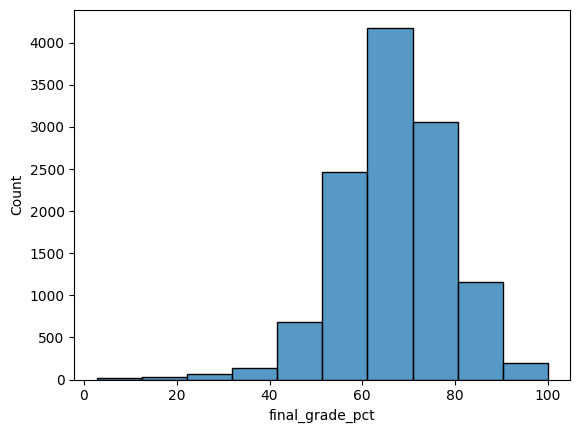

In [9]:
import seaborn as sns
sns.histplot(df['final_grade_pct'], bins=10)

This graph above shows what the final grace percentage was and how many students achieved that final grade percentage. It shows majority of the students fell in between the 60% to 70% range. The final grade average mentioned above is 66.95% which shows that this histogram is accurate. This shows a good visual of where all the students fall.

<Axes: xlabel='gender', ylabel='final_grade_pct'>

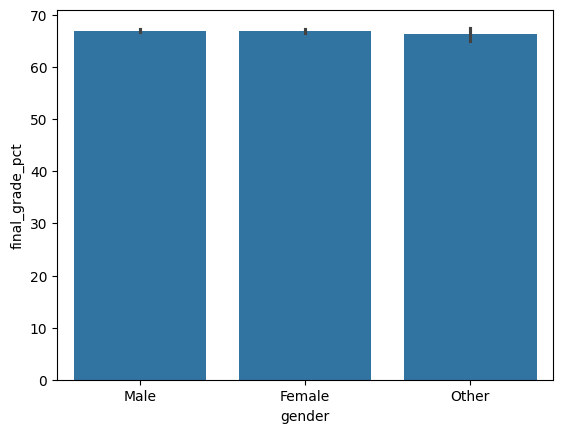

In [10]:
sns.barplot(x='gender', y='final_grade_pct', data=df)

The graph above shows a bar plot comparing the final grade between genders. All three bars are pretty similar which showcases that gender does not have a large effect on the final grades of students.

---



<Axes: xlabel='annual_family_income_inr', ylabel='final_grade_pct'>

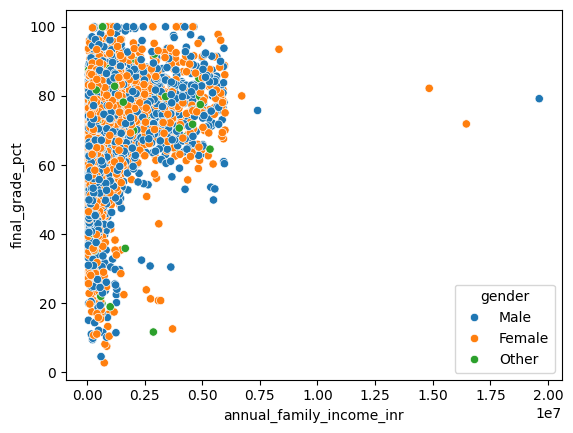

In [11]:
sns.scatterplot(x='annual_family_income_inr', y='final_grade_pct', hue='gender', data=df)

The graph above explores the relationship between final grade percentage and family income. There is some correlation that is there, however there is a lot of variation. Gender does not seem to have an effect.

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.isnull().sum()

student_id                      0
academic_year                   0
survey_date                     0
age                             0
gender                          0
grade_level                     0
school_type                     0
residence_type                  0
family_size                     0
num_siblings                    0
single_parent_household         0
family_income_bracket           0
annual_family_income_inr      720
father_education_level        420
mother_education_level        360
father_occupation             480
mother_occupation             600
has_internet_access           180
has_computer_or_laptop          0
distance_to_school_km         240
scholarship_status              0
extra_tutoring                  0
parental_involvement_score      0
study_hours_per_week            0
attendance_rate_pct           300
previous_year_grade_pct       360
final_grade_pct                 0
grade_class                     0
at_risk_flag                    0
dtype: int64

In [14]:
df = df.dropna()


df.shape

(8785, 29)

In order to get the data ready to split, we checked for duplicated and removed any students that had any missing information to make sure we have even data to work with.

**NAIVE BENCHMARK MODEL**

In [15]:
# Core libs
!pip install dmba
import dmba
import numpy as np
import pandas as pd

# Modeling + evaluation
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

zsh:1: command not found: pip


In [16]:
# Drop duplicates and rows with missing values again here, so this cell is safe even if
# cells were run out of order (otherwise the baseline fails with "Input X contains NaN").
# When the notebook runs top to bottom this changes nothing: 8,785 complete rows either way.
df = df.drop_duplicates().dropna()

X = df.drop(columns=['final_grade_pct', 'grade_class',
                     'at_risk_flag', 'student_id', 'survey_date'])
y = df['final_grade_pct']

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [18]:
num_features = ["age", "grade_level", "family_size", "num_siblings",
                "single_parent_household", "annual_family_income_inr",
                "has_internet_access", "has_computer_or_laptop",
                "distance_to_school_km", "extra_tutoring",
                "parental_involvement_score", "study_hours_per_week",
                "attendance_rate_pct", "previous_year_grade_pct"]

cat_features = ["academic_year", "gender", "school_type",
                "residence_type", "family_income_bracket",
                "father_education_level", "mother_education_level",
                "father_occupation", "mother_occupation",
                "scholarship_status"]


In [19]:
preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(drop='first', handle_unknown='ignore'), cat_features)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

In [20]:
y_pred_naive = np.repeat(y_train.mean(), len(y_test))
regressionSummary(y_test, y_pred_naive)


Regression statistics

                      Mean Error (ME) : 0.2085
       Root Mean Squared Error (RMSE) : 11.2492
            Mean Absolute Error (MAE) : 8.7151
          Mean Percentage Error (MPE) : -4.4934
Mean Absolute Percentage Error (MAPE) : 15.7116


For the naive benchmark model, we decided to explore the average final grade. This model will help us evaluate our other models to see what performs best at the end of this notebook. Our MAE is 8.72 meaning that's how off our predictions are from the average. THE RMSE came out to be 11.25 meaning larger predictions are focused on.

**BASELINE MODEL**

In [21]:
from sklearn.linear_model import LinearRegression

baseline = Pipeline([('preprocess', preprocess),
                     ('model', LinearRegression())])

In [22]:
baseline.fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)
regressionSummary(y_test, y_pred_baseline)


Regression statistics

                      Mean Error (ME) : 0.2685
       Root Mean Squared Error (RMSE) : 9.3407
            Mean Absolute Error (MAE) : 6.9137
          Mean Percentage Error (MPE) : -3.7405
Mean Absolute Percentage Error (MAPE) : 13.1646


1. The RMSE dropped from 11.2492 in the naive to 9.3407 in the baseline which shows that the baseline makes smaller errors
2. MAE also dropped from 8.7151 in the naive to 6.9137 in the baseline so the baseline makes smaller overall errors
3. MAPE is also lower for the baseline by 2.55 percentage points which is another datapoint to show that the baseline makes smaller mistakes compared to the naive

**PRELIMINARY PERFORMANCE EVALUATION**

Both models are evaluated on the same **single train/test split** (80% train / 20% test, `random_state=42`), as Milestone 1 requires. Cross-validation and tuning come in Milestone 2. All preprocessing (scaling and one-hot encoding) is fitted inside the pipeline on the **training data only**, and the naïve model's prediction is the **training** mean, so no test information leaks into either model.

We report four metrics on the 1,757 test students:
- **RMSE**: the typical error, with large misses weighted more heavily
- **MAE**: the average size of a miss, in grade-percentage points
- **MAPE**: the average miss as a percentage of the student's actual grade
- **R²**: the share of the variation in final grades that the model explains

In [23]:
# Preliminary performance evaluation on the single held-out test set
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

def evaluate(name, y_true, y_pred):
    """Return the test-set metrics for one model as a dictionary."""
    return {
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MAPE (%)": 100 * mean_absolute_percentage_error(y_true, y_pred),
        "R²": r2_score(y_true, y_pred),
    }

performance = pd.DataFrame([
    evaluate("Naïve (training mean)", y_test, y_pred_naive),
    evaluate("Baseline (linear regression)", y_test, y_pred_baseline),
]).set_index("Model")

print(f"Test students: {len(y_test):,}")
performance.round(4)

Test students: 1,757


,RMSE,MAE,MAPE (%),R²
Model,,,,
Naïve (training mean),11.2492,8.7151,15.7116,-0.0003
Baseline (linear regression),9.3407,6.9137,13.1646,0.3103


**Interpretation of the performance results**

- **The baseline beats the naïve model on every metric.**
  - RMSE falls from **11.25 to 9.34** points (−17.0%).
  - MAE falls from **8.72 to 6.91** points (−20.7%).
  - MAPE falls from **15.7% to 13.2%**.
- **The naïve model explains none of the variation (R² ≈ 0.00).** That is expected: it gives every student the same prediction.
- **Linear regression explains about 31% of it (R² ≈ 0.31).** Attendance, study hours, previous-year grade and family background carry real signal about a student's final grade.
- **About 69% of the variation is still unexplained**, so there is clear room for the Milestone 2 models (for example random forest or boosting) to capture non-linear effects.
- **Both models' mean errors are close to zero** (0.21 and 0.27 points in the regression summaries above). Neither model is systematically biased high or low; the gain comes from the baseline separating stronger and weaker students.

**EXPLICIT VALUE CALCULATION FOR EACH MODEL**

**How a school would use the prediction.** At the start of a term, a counselor uses each student's predicted final grade to decide how much tutoring support that student gets. The dataset already records `extra_tutoring`, so this decision really happens. A prediction that is **too high** means a struggling student gets too little help. A prediction that is **too low** means tutor time goes to a student who didn't need it. Either way, **every percentage point of prediction error misallocates tutoring.**

**Value definition (cost of error):**

$$\text{Cost per student} = \text{MAE (grade points)} \times \text{cost per grade point of error}$$

**Assumptions** (approximate, as Milestone 1 allows; the dataset is from India, so costs are in rupees):
- A tutoring hour costs about **₹600**.
- Each percentage point of error misallocates about **0.5 tutoring hours** per student per term.
- So each grade point of error costs **₹300** per student per term.

A model's **value** is how much of this cost it avoids compared with having no model (the naïve benchmark).

In [24]:
# Explicit value calculation for each model
TUTOR_HOUR_COST_INR = 600        # assumption: cost of one tutoring hour (₹)
HOURS_PER_POINT_OF_ERROR = 0.5   # assumption: tutoring hours misallocated per grade point of error
COST_PER_POINT_INR = TUTOR_HOUR_COST_INR * HOURS_PER_POINT_OF_ERROR   # ₹300 per point, per student, per term

n_test = len(y_test)

def model_value(name, y_true, y_pred, cost_per_point=COST_PER_POINT_INR):
    """Cost of prediction error for one model, per student and for the whole test set."""
    mae = mean_absolute_error(y_true, y_pred)
    cost_per_student = mae * cost_per_point
    return {
        "Model": name,
        "MAE (points)": mae,
        "Cost per student (₹)": cost_per_student,
        "Cost, test set (₹)": cost_per_student * len(y_true),
        "Cost per 1,000 students (₹)": cost_per_student * 1000,
    }

value = pd.DataFrame([
    model_value("Naïve (training mean)", y_test, y_pred_naive),
    model_value("Baseline (linear regression)", y_test, y_pred_baseline),
]).set_index("Model")

print(f"Assumed cost per grade point of error: ₹{COST_PER_POINT_INR:,.0f} per student per term; test students: {n_test:,}")
value.round(2)

Assumed cost per grade point of error: ₹300 per student per term; test students: 1,757


,MAE (points),Cost per student (₹),"Cost, test set (₹)","Cost per 1,000 students (₹)"
Model,,,,
Naïve (training mean),8.72,2614.54,4593752.05,2614543.00
Baseline (linear regression),6.91,2074.12,3644223.48,2074116.95


**Value of each model (test set, ₹300 per grade point of error):**

| Model | MAE (points) | Cost of error per student | Cost for the 1,757 test students |
| --- | --- | --- | --- |
| Naïve (training mean) | 8.72 | **₹2,614.54** | ₹4,593,752 |
| Baseline (linear regression) | 6.91 | **₹2,074.12** | ₹3,644,223 |

- **The naïve model is the "no model" reference.** Predicting the average grade for everyone still misallocates about ₹2,615 of tutoring per student per term.
- **The baseline cuts that to about ₹2,074 per student**, because its predictions are on average 1.8 points closer to each student's real grade.

**COMPARISON OF NAÏVE VS BASELINE MODEL IN TERMS OF VALUE**

Saving per student per term:      ₹540.43
Reduction in cost of error:       20.7%
Saving across the test set:       ₹949,529  (1,757 students)
Saving per 1,000 students:        ₹540,426
Reduction if cost grows with squared error (MSE): 31.1%


,Cost per grade point (₹),Saving per student (₹),"Saving per 1,000 students (₹)"
0,100,180.14,180142.02
1,300,540.43,540426.05
2,600,1080.85,1080852.10


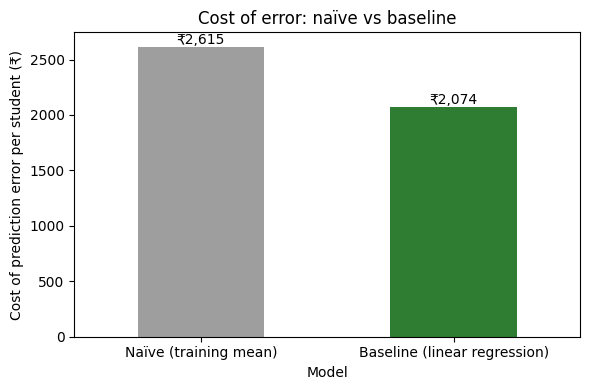

In [25]:
# Value created by the baseline compared with the naïve benchmark
naive_cost = value.loc["Naïve (training mean)", "Cost per student (₹)"]
baseline_cost = value.loc["Baseline (linear regression)", "Cost per student (₹)"]
saving_per_student = naive_cost - baseline_cost

print(f"Saving per student per term:      ₹{saving_per_student:,.2f}")
print(f"Reduction in cost of error:       {saving_per_student / naive_cost:.1%}")
print(f"Saving across the test set:       ₹{saving_per_student * n_test:,.0f}  ({n_test:,} students)")
print(f"Saving per 1,000 students:        ₹{saving_per_student * 1000:,.0f}")

# If large misses hurt more than small ones (cost grows with the squared error),
# the value comparison uses MSE instead of MAE.
mse_naive = mean_squared_error(y_test, y_pred_naive)
mse_baseline = mean_squared_error(y_test, y_pred_baseline)
print(f"Reduction if cost grows with squared error (MSE): {1 - mse_baseline / mse_naive:.1%}")

# Sensitivity: the saving depends on the assumed cost per grade point
sensitivity = pd.DataFrame({"Cost per grade point (₹)": [100, 300, 600]})
mae_gap = mean_absolute_error(y_test, y_pred_naive) - mean_absolute_error(y_test, y_pred_baseline)
sensitivity["Saving per student (₹)"] = sensitivity["Cost per grade point (₹)"] * mae_gap
sensitivity["Saving per 1,000 students (₹)"] = sensitivity["Saving per student (₹)"] * 1000
display(sensitivity.round(2))

# Visual comparison of the cost of error per student
ax = value["Cost per student (₹)"].plot(kind="bar", color=["#9e9e9e", "#2e7d32"], rot=0, figsize=(6, 4))
ax.set_ylabel("Cost of prediction error per student (₹)")
ax.set_title("Cost of error: naïve vs baseline")
for bar in ax.patches:
    ax.annotate(f"₹{bar.get_height():,.0f}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()

**Interpretation of the value comparison**

- **The baseline creates value.** It saves about **₹540 per student per term** compared with the naïve benchmark: a **20.7% reduction** in the cost of prediction error.
  - Across the 1,757 test students, that's about **₹949,529** of tutoring time put to better use.
  - Per 1,000 students, it's about **₹540,426**.
- **If large misses are costlier than small ones**, which is plausible because missing a failing student matters more than a 1-point miss, the value comparison uses squared error. On that basis the baseline cuts the cost of error by about **31%** (MSE falls from about 126.5 to 87.2). That makes the baseline's advantage larger, not smaller.
- **The conclusion holds whatever the assumed cost.** The saving scales directly with the cost per grade point: about ₹180, ₹540 or ₹1,081 per student at ₹100, ₹300 or ₹600 per point. The exact rupee figure depends on the assumption, but **the baseline is always worth more than the naïve model, because its MAE is 1.80 points lower.**

**Limitations of this preliminary value estimate**
- **The cost assumptions are illustrative**, not taken from a school's budget. A real tutoring cost and real hours-per-point figure would change the rupee values, not the ranking.
- **It treats over- and under-predictions as equally costly.** In practice, under-supporting a struggling student is probably worse. Milestone 2 can test an asymmetric cost, or a classification of at-risk students (`at_risk_flag`).
- **It's based on one train/test split.** Milestone 2 will check these values with cross-validation.
- **Rows with any missing value were dropped** (12,025 → 8,785 after removing duplicates and missing data). The model is evaluated only on students with complete records, which may not represent students with missing information.